# Music genre classification with a CNN on log-mel spectrograms

Pipeline: split GTZAN by track (70/15/15) -> 3 s log-mel segments -> random search over hop length and
architecture (validation only) -> final model from the best configuration -> one evaluation on the test set
(segment and track level) -> evaluation on 50 commercial songs with soft voting.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, sys, json, random, shutil
import numpy as np
import librosa
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from sklearn.model_selection import train_test_split

IN_COLAB = 'google.colab' in sys.modules

# Paths: override with environment variables or edit here
if IN_COLAB:
    %pip install -q keras-tuner
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = os.environ.get('PROJECT_DIR', '/content/drive/MyDrive/SupervisedProject')
    DATA_DIR = os.environ.get('DATA_DIR', '/content/dataset/genres')
    if not os.path.exists(DATA_DIR):
        print("Extracting dataset")
        shutil.unpack_archive(os.path.join(PROJECT_DIR, 'dataset.zip'), '/content/dataset')
else:
    PROJECT_DIR = os.environ.get('PROJECT_DIR', '..')
    DATA_DIR = os.environ.get('DATA_DIR', os.path.join(PROJECT_DIR, 'data', 'genres'))
SONGS_DIR = os.environ.get('SONGS_DIR', os.path.join(PROJECT_DIR, 'test examples'))
OUTPUT_DIR = os.path.join(PROJECT_DIR, 'outputs')
FIGURES_DIR = os.path.join(OUTPUT_DIR, 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

device_name = "/GPU:0" if tf.config.list_physical_devices('GPU') else "/CPU:0"
print(f"Data: {DATA_DIR} | Device: {device_name}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Extracting dataset
Data: /content/dataset/genres | Device: /GPU:0


We are using the GTZAN dataset (Tzanetakis & Cook, 2002): 1000 clips of 30 s, 10 genres, 100 clips each.
https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification

`DATA_DIR` must contain one folder per genre (`.au` original or Kaggle `.wav` copy).

In [3]:
SAMPLE_RATE = 22050
TRACK_DURATION = 30
SAMPLES_PER_TRACK = SAMPLE_RATE * TRACK_DURATION
NUM_SEGMENTS = 10

samples_per_segment = int(SAMPLES_PER_TRACK / NUM_SEGMENTS)

genres = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])
NUM_CLASSES = len(genres)

VALID_EXTENSIONS = ('.wav', '.au', '.mp3', '.m4a')

# jazz.00054 is unreadable in the widely used Kaggle .wav copy of GTZAN.
# It is excluded by name so that both copies use the same 999-track list.
KNOWN_CORRUPT = {'jazz.00054'}


def list_tracks(data_dir, genres):
    paths, labels = [], []
    for label_idx, genre in enumerate(genres):
        genre_folder = os.path.join(data_dir, genre)
        audio_files = sorted(f for f in os.listdir(genre_folder) if f.lower().endswith(VALID_EXTENSIONS) and not f.startswith('._'))
        print(f" -> Genre '{genre}': Found {len(audio_files)} valid audio tracks.")
        for f in audio_files:
            if os.path.splitext(f)[0] in KNOWN_CORRUPT:
                print(f"    Excluding known corrupted file: {f}")
                continue
            paths.append(os.path.join(genre_folder, f))
            labels.append(label_idx)
    return np.array(paths), np.array(labels)


def extract_segments(paths, labels, hop_length):
    X, y, track_ids = [], [], []
    for t, (file_path, label) in enumerate(zip(paths, labels)):
        signal, sr = librosa.load(file_path, sr=SAMPLE_RATE, mono=True)

        for d in range(NUM_SEGMENTS):
            start = samples_per_segment * d
            finish = start + samples_per_segment
            audio_segment = signal[start:finish]

            # Skip the last segment of tracks slightly shorter than 30 s
            if len(audio_segment) < samples_per_segment:
                continue

            mel = librosa.feature.melspectrogram(y=audio_segment, sr=sr, n_fft=2048, hop_length=hop_length, n_mels=128)
            X.append(librosa.power_to_db(mel, ref=np.max))
            y.append(label)
            track_ids.append(t)

    return np.array(X)[..., np.newaxis], np.array(y), np.array(track_ids)


print(f"Processing raw audio files from: {DATA_DIR}\n")
paths, labels = list_tracks(DATA_DIR, genres)

# Split the TRACK list 70/15/15 (stratified by genre) BEFORE segmenting,
# so all segments of one track end up in exactly one split.
p_train, p_tmp, l_train, l_tmp = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_val, p_test, l_val, l_test = train_test_split(p_tmp, l_tmp, test_size=0.50, stratify=l_tmp, random_state=SEED)

assert not set(p_train) & set(p_val)
assert not set(p_train) & set(p_test)
assert not set(p_val) & set(p_test)
print(f"\nTracks - train: {len(p_train)}, val: {len(p_val)}, test: {len(p_test)}")

Processing raw audio files from: /content/dataset/genres

 -> Genre 'blues': Found 100 valid audio tracks.
 -> Genre 'classical': Found 100 valid audio tracks.
 -> Genre 'country': Found 100 valid audio tracks.
 -> Genre 'disco': Found 100 valid audio tracks.
 -> Genre 'hiphop': Found 100 valid audio tracks.
 -> Genre 'jazz': Found 100 valid audio tracks.
    Excluding known corrupted file: jazz.00054.au
 -> Genre 'metal': Found 100 valid audio tracks.
 -> Genre 'pop': Found 100 valid audio tracks.
 -> Genre 'reggae': Found 100 valid audio tracks.
 -> Genre 'rock': Found 100 valid audio tracks.

Tracks - train: 699, val: 150, test: 150


Each split is segmented separately into 3 s log-mel spectrograms of shape (128, frames, 1).
No track contributes segments to more than one split. Tracks per genre in each split:

In [4]:
for name, l in [('train', l_train), ('val', l_val), ('test', l_test)]:
    print(f"{name:>5}: {np.bincount(l, minlength=NUM_CLASSES)}")

train: [70 70 70 70 70 69 70 70 70 70]
  val: [15 15 15 15 15 15 15 15 15 15]
 test: [15 15 15 15 15 15 15 15 15 15]


Visual check: MFCC vs. log-mel spectrogram of one 3 s training segment.

VISUAL INSPECTION FOR GENRE: REGGAE


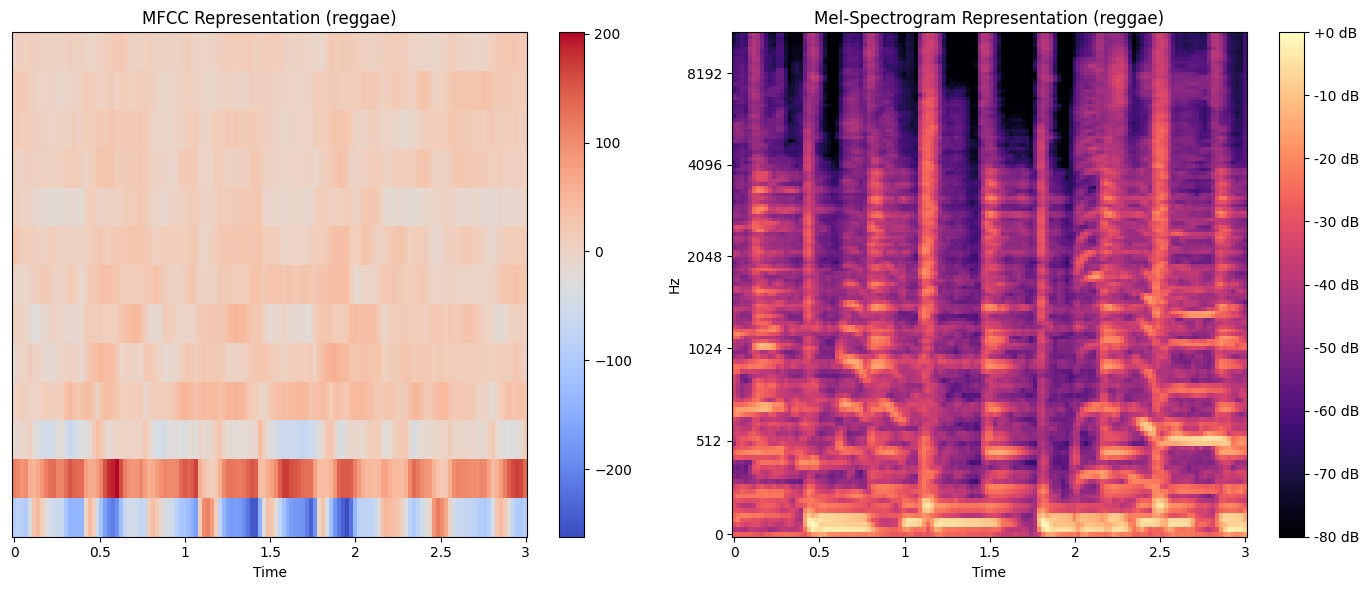

In [5]:
import matplotlib.pyplot as plt
import librosa.display

sample_signal, _ = librosa.load(p_train[0], sr=SAMPLE_RATE, mono=True)
sample_segment = sample_signal[:samples_per_segment]
sample_mfcc = librosa.feature.mfcc(y=sample_segment, sr=SAMPLE_RATE, n_fft=2048, hop_length=512, n_mfcc=13)
sample_mel_db = librosa.power_to_db(librosa.feature.melspectrogram(y=sample_segment, sr=SAMPLE_RATE, n_fft=2048, hop_length=512, n_mels=128), ref=np.max)
sample_genre_name = genres[l_train[0]]

print(f"VISUAL INSPECTION FOR GENRE: {sample_genre_name.upper()}")
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
librosa.display.specshow(sample_mfcc, sr=SAMPLE_RATE, hop_length=512, x_axis='time')
plt.title(f"MFCC Representation ({sample_genre_name})")
plt.colorbar()

plt.subplot(1, 2, 2)
librosa.display.specshow(sample_mel_db, sr=SAMPLE_RATE, hop_length=512, x_axis='time', y_axis='mel')
plt.title(f"Mel-Spectrogram Representation ({sample_genre_name})")
plt.colorbar(format="%+2.0f dB")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'spectrogram.png'), dpi=150)
plt.show()

CNN architecture. The same function builds the models in the hyperparameter search and the final model,
so the final model uses exactly the configuration the search selected.

In [6]:
def build_cnn(config, input_shape, num_classes):
    model = models.Sequential([layers.Input(shape=input_shape)])

    for i in range(config['num_conv_blocks']):
        model.add(layers.Conv2D(config[f'filters_{i}'], (3, 3), activation='relu', padding='same'))
        model.add(layers.MaxPooling2D((2, 2), padding='same'))
        model.add(layers.BatchNormalization())

    model.add(layers.Flatten())
    model.add(layers.Dense(config['dense_units'], activation='relu'))
    model.add(layers.Dropout(config['dropout_rate']))
    model.add(layers.Dense(num_classes, activation='softmax'))

    model.compile(optimizer=optimizers.Adam(learning_rate=config['learning_rate']),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

Random search (20 trials per hop length, up to 30 epochs with early stopping). Hop length and architecture
are selected by validation accuracy only; the test set is not used here.
The tuner state is stored in `OUTPUT_DIR`, so an interrupted Colab run resumes where it stopped.

In [7]:
import keras_tuner as kt

HOP_LENGTH_OPTIONS = [512, 256]
MAX_TRIALS = 20

best_overall_val = 0.0
val_acc_per_hop = {}
best_overall_config = {}

for current_hop in HOP_LENGTH_OPTIONS:

    # Same track split as cell 2; the test tracks are not used here at all
    print(f"\nExtracting audio features with Hop Length: {current_hop}")
    X_train, y_train, _ = extract_segments(p_train, l_train, current_hop)
    X_val, y_val, _ = extract_segments(p_val, l_val, current_hop)
    current_width = X_train.shape[2]
    tf.keras.backend.clear_session()

    def build_tunable_model(hp):
        config = {'num_conv_blocks': hp.Int('num_conv_blocks', min_value=2, max_value=3)}
        for i in range(config['num_conv_blocks']):
            config[f'filters_{i}'] = hp.Choice(f'filters_{i}', values=[32, 64, 128])
        config['dense_units'] = hp.Choice('dense_units', values=[64, 128])
        config['dropout_rate'] = hp.Float('dropout_rate', min_value=0.3, max_value=0.5, step=0.1)
        config['learning_rate'] = hp.Choice('learning_rate', values=[1e-3, 1e-4])
        return build_cnn(config, (128, current_width, 1), NUM_CLASSES)

    tuner = kt.RandomSearch(
        build_tunable_model,
        objective='val_accuracy',
        max_trials=MAX_TRIALS,
        seed=SEED,
        directory=os.path.join(OUTPUT_DIR, 'tuning'),
        project_name=f'hop_{current_hop}_tracksplit'
    )

    early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

    print(f"Initiating Architecture Search for Hop Length {current_hop}")

    with tf.device(device_name):
        tuner.search(X_train, y_train, epochs=30, validation_data=(X_val, y_val), callbacks=[early_stop], verbose=1)

    best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
    best_val_acc = tuner.oracle.get_best_trials(num_trials=1)[0].score

    print(f"Best setup for Hop Length {current_hop} scored Validation Accuracy: {best_val_acc*100:.2f}%")

    val_acc_per_hop[current_hop] = best_val_acc

    # Selection uses validation accuracy only; the test set is evaluated once at the end
    if best_val_acc > best_overall_val:
        best_overall_val = best_val_acc
        best_overall_config = {'hop_length': current_hop, **best_hp.values}

# keras_tuner clears the cell output during search, so repeat the per-hop results here
print("EXPERIMENTAL SUMMARY")
for hop, acc in val_acc_per_hop.items():
    print(f" Hop Length {hop}: best validation accuracy {acc*100:.2f}%")
print(f"Highest Validation Accuracy: {best_overall_val*100:.2f}%")
print("\nOptimal Parameter Blueprint:")
for parameter, value in best_overall_config.items():
    print(f" -> {parameter.upper()}: {value}")

with open(os.path.join(OUTPUT_DIR, 'best_config.json'), 'w') as f:
    json.dump(best_overall_config, f, indent=2)

Trial 20 Complete [00h 02m 37s]
val_accuracy: 0.7206666469573975

Best val_accuracy So Far: 0.7406666874885559
Total elapsed time: 01h 18m 59s
Best setup for Hop Length 256 scored Validation Accuracy: 74.07%
EXPERIMENTAL SUMMARY
 Hop Length 512: best validation accuracy 76.87%
 Hop Length 256: best validation accuracy 74.07%
Highest Validation Accuracy: 76.87%

Optimal Parameter Blueprint:
 -> HOP_LENGTH: 512
 -> NUM_CONV_BLOCKS: 3
 -> FILTERS_0: 32
 -> FILTERS_1: 64
 -> DENSE_UNITS: 64
 -> DROPOUT_RATE: 0.5
 -> LEARNING_RATE: 0.001
 -> FILTERS_2: 32


Final model, built only from `best_config.json` and trained on the training tracks (validation for early stopping).

In [8]:
from tensorflow.keras.callbacks import EarlyStopping

with open(os.path.join(OUTPUT_DIR, 'best_config.json')) as f:
    best_config = json.load(f)
HOP = best_config['hop_length']
print(best_config)

X_train, y_train, _ = extract_segments(p_train, l_train, HOP)
X_val, y_val, _ = extract_segments(p_val, l_val, HOP)
print(f"Segments - train: {len(X_train)}, val: {len(X_val)} | resolution: {X_train.shape[1]}x{X_train.shape[2]}")

tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

with tf.device(device_name):
    final_model = build_cnn(best_config, X_train.shape[1:], NUM_CLASSES)
    early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    history = final_model.fit(X_train, y_train,
                              validation_data=(X_val, y_val),
                              batch_size=32,
                              epochs=40,
                              callbacks=[early_stop])

final_model.summary()
final_model.save(os.path.join(OUTPUT_DIR, 'final_model.keras'))

{'hop_length': 512, 'num_conv_blocks': 3, 'filters_0': 32, 'filters_1': 64, 'dense_units': 64, 'dropout_rate': 0.5, 'learning_rate': 0.001, 'filters_2': 32}
Segments - train: 6982, val: 1500 | resolution: 128x130
Epoch 1/40
219/219 ━━━━━━━━━━━━━━━━━━━━ 16s 48ms/step - accuracy: 0.1283 - loss: 2.2826 - val_accuracy: 0.2020 - val_loss: 2.1866
Epoch 2/40
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.1873 - loss: 2.1251 - val_accuracy: 0.2733 - val_loss: 1.8864
Epoch 3/40
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.2070 - loss: 2.0549 - val_accuracy: 0.3420 - val_loss: 1.8138
Epoch 4/40
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.2286 - loss: 2.0172 - val_accuracy: 0.2073 - val_loss: 2.0578
Epoch 5/40
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.2282 - loss: 2.0111 - val_accuracy: 0.3080 - val_loss: 1.8579
Epoch 6/40
219/219 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.2453 - loss: 1.9729 - val_accuracy: 0.3633 - val_loss: 1.6834
Epoch 7/40
2

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 130, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 65, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 65, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 65, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 33, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 33, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 33, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 17, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 17, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8704)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       557,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,786,176 (6.81 MB)

 Trainable params: 595,306 (2.27 MB)

 Non-trainable params: 256 (1.00 KB)

 Optimizer params: 1,190,614 (4.54 MB)

Evaluation on the held-out test tracks (the only time the test set is used).
Track-level accuracy averages each track's segment probabilities (soft voting), the same rule as for the real songs.

47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step
Segment-level test accuracy: 68.78% (1499 segments)
Track-level test accuracy:   77.33% (150 tracks)

--- DETAILED PERFORMANCE REPORT (segment level) ---
              precision    recall  f1-score   support

       blues       0.63      0.85      0.72       150
   classical       0.75      0.95      0.84       149
     country       0.50      0.72      0.59       150
       disco       0.68      0.52      0.59       150
      hiphop       0.70      0.50      0.58       150
        jazz       0.78      0.87      0.83       150
       metal       0.87      0.81      0.84       150
         pop       0.87      0.74      0.80       150
      reggae       0.69      0.57      0.62       150
        rock       0.46      0.35      0.40       150

    accuracy                           0.69      1499
   macro avg       0.69      0.69      0.68      1499
weighted avg       0.69      0.69      0.68      1499



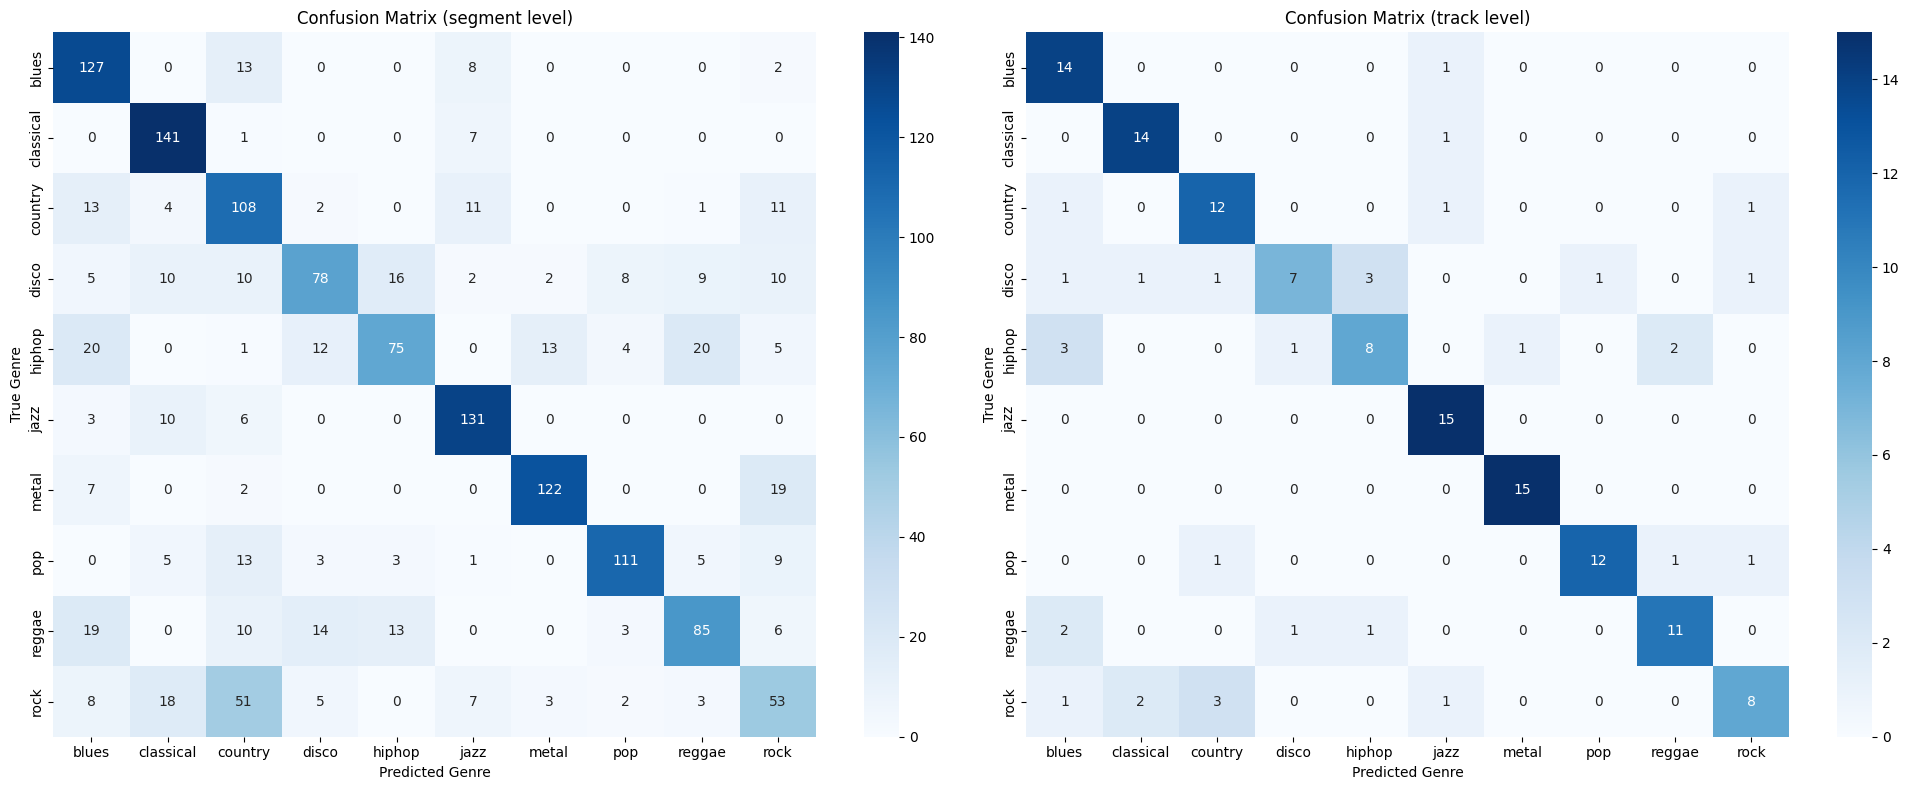

In [9]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# First and only use of the test set
X_test, y_test, t_test = extract_segments(p_test, l_test, HOP)

y_pred_raw = final_model.predict(X_test)
y_pred = np.argmax(y_pred_raw, axis=1)

# Track level: average each track's segment probabilities (soft voting)
track_probs = np.zeros((len(p_test), NUM_CLASSES))
np.add.at(track_probs, t_test, y_pred_raw)
track_probs /= np.bincount(t_test, minlength=len(p_test))[:, None]
track_pred = np.argmax(track_probs, axis=1)

segment_acc = np.mean(y_pred == y_test)
track_acc = np.mean(track_pred == l_test)
print(f"Segment-level test accuracy: {segment_acc*100:.2f}% ({len(y_test)} segments)")
print(f"Track-level test accuracy:   {track_acc*100:.2f}% ({len(l_test)} tracks)")

print("\n--- DETAILED PERFORMANCE REPORT (segment level) ---")
print(classification_report(y_test, y_pred, target_names=genres, digits=2))

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, (true, pred, level) in zip(axes, [(y_test, y_pred, 'segment'), (l_test, track_pred, 'track')]):
    sns.heatmap(confusion_matrix(true, pred), annot=True, fmt='d', xticklabels=genres, yticklabels=genres, cmap='Blues', ax=ax)
    ax.set_xlabel('Predicted Genre')
    ax.set_ylabel('True Genre')
    ax.set_title(f'Confusion Matrix ({level} level)')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'confusion_matrix.png'), dpi=150)
plt.show()

with open(os.path.join(OUTPUT_DIR, 'test_results.json'), 'w') as f:
    json.dump({'segment_accuracy': float(segment_acc), 'track_accuracy': float(track_acc),
               'n_test_segments': int(len(y_test)), 'n_test_tracks': int(len(l_test))}, f, indent=2)

Real-world test: 50 commercial songs (5 per genre). Each song is cut into 3 s segments and the segment probabilities are averaged (soft voting).

In [10]:
def predict_genre_of_file(file_path, model, genres_list, hop_length):
    try:
        signal, sr = librosa.load(file_path, sr=SAMPLE_RATE, mono=True)
    except Exception as e:
        return None, f"Error reading audio: {e}"

    file_segments = []

    num_possible_segments = len(signal) // samples_per_segment

    for d in range(num_possible_segments):
        start = samples_per_segment * d
        finish = start + samples_per_segment
        audio_segment = signal[start:finish]

        mel = librosa.feature.melspectrogram(y=audio_segment, sr=sr, n_fft=2048, hop_length=hop_length, n_mels=128)
        file_segments.append(librosa.power_to_db(mel, ref=np.max))

    if len(file_segments) == 0:
        return None, "Audio file - zero valid segments."

    # Format for CNN input shape: (NumSegments, 128, frames, 1)
    X_new = np.array(file_segments)
    X_new = X_new[..., np.newaxis]

    predictions = model.predict(X_new, verbose=0)

    average_predictions = np.mean(predictions, axis=0)
    predicted_class_idx = np.argmax(average_predictions)
    predicted_genre = genres_list[predicted_class_idx]

    return predicted_genre, average_predictions


TEST_EXAMPLES_PATH = SONGS_DIR

detailed_results = []
total_songs = 0
correct_songs = 0


if not os.path.exists(TEST_EXAMPLES_PATH):
    print(f"Target path not found")
else:
    subfolders = sorted([d for d in os.listdir(TEST_EXAMPLES_PATH) if os.path.isdir(os.path.join(TEST_EXAMPLES_PATH, d))])

    for folder_name in subfolders:
        folder_path = os.path.join(TEST_EXAMPLES_PATH, folder_name)

        true_genre = folder_name.lower().strip()
        if true_genre == "reggea":
            true_genre = "reggae"

        audio_files = sorted(f for f in os.listdir(folder_path) if f.lower().endswith(VALID_EXTENSIONS) and not f.startswith('._'))
        print(f"Entering Subfolder '{folder_name}' | Found {len(audio_files)} track assets")

        for file_name in audio_files:
            file_path = os.path.join(folder_path, file_name)
            total_songs += 1

            predicted_genre, confidences = predict_genre_of_file(file_path, final_model, genres, HOP)

            if predicted_genre is None:
                print(f"Skipping Track '{file_name}': {confidences}")
                detailed_results.append({
                    'filename': file_name, 'true_genre': true_genre, 'predicted_genre': "ERROR",
                    'status': "FAILED", 'confidences': None
                })
                continue

            is_correct = (predicted_genre.lower() == true_genre)
            if is_correct:
                correct_songs += 1
                status_text = "CORRECT"
            else:
                status_text = "INCORRECT"

            detailed_results.append({
                'filename': file_name,
                'true_genre': true_genre,
                'predicted_genre': predicted_genre,
                'status': status_text,
                'confidences': confidences
            })
            print(f"   ↳ [PREDICTED]: {predicted_genre.upper():<10} | {status_text}")

    print("FINAL REPORT")

    accuracy_percentage = (correct_songs / total_songs) * 100 if total_songs > 0 else 0
    print(f"Total Evaluation Sample Volume: {total_songs} Tracks")
    print(f"Total System Matches:          {correct_songs} / {total_songs} Songs Classified Correctly")
    print(f"Custom Target Set Accuracy:    {accuracy_percentage:.2f}%")

    print("\nINDIVIDUAL TRACK BREAKDOWNS")
    for report in detailed_results:
        print(f"\nFile: {report['filename']}")
        print(f"[Target: {report['true_genre'].upper()}] → [Predicted: {report['predicted_genre'].upper()}] | {report['status']}")

        if report['confidences'] is not None:
            print("Softmax Confidence Distributions:")
            probability_strings = [f"{genres[i].upper()}: {prob*100:.1f}%" for i, prob in enumerate(report['confidences'])]
            for step in range(0, len(probability_strings), 3):
                print("      • " + "  |  ".join(probability_strings[step:step+3]))


    with open(os.path.join(OUTPUT_DIR, 'real_songs_results.json'), 'w') as f:
        json.dump({'accuracy': correct_songs / total_songs, 'correct': correct_songs, 'total': total_songs,
                   'songs': [{k: v for k, v in rep.items() if k != 'confidences'} for rep in detailed_results]},
                  f, indent=2, ensure_ascii=False)

Entering Subfolder 'blues' | Found 5 track assets
   ↳ [PREDICTED]: COUNTRY    | INCORRECT
   ↳ [PREDICTED]: BLUES      | CORRECT
   ↳ [PREDICTED]: BLUES      | CORRECT
   ↳ [PREDICTED]: JAZZ       | INCORRECT
   ↳ [PREDICTED]: COUNTRY    | INCORRECT
Entering Subfolder 'classical' | Found 5 track assets
   ↳ [PREDICTED]: CLASSICAL  | CORRECT
   ↳ [PREDICTED]: CLASSICAL  | CORRECT
   ↳ [PREDICTED]: CLASSICAL  | CORRECT
   ↳ [PREDICTED]: CLASSICAL  | CORRECT
   ↳ [PREDICTED]: CLASSICAL  | CORRECT
Entering Subfolder 'country' | Found 5 track assets
   ↳ [PREDICTED]: COUNTRY    | CORRECT
   ↳ [PREDICTED]: CLASSICAL  | INCORRECT
   ↳ [PREDICTED]: JAZZ       | INCORRECT
   ↳ [PREDICTED]: JAZZ       | INCORRECT
   ↳ [PREDICTED]: COUNTRY    | CORRECT
Entering Subfolder 'disco' | Found 5 track assets
   ↳ [PREDICTED]: DISCO      | CORRECT
   ↳ [PREDICTED]: DISCO      | CORRECT
   ↳ [PREDICTED]: DISCO      | CORRECT
   ↳ [PREDICTED]: DISCO      | CORRECT
   ↳ [PREDICTED]: DISCO      | CORRECT
En